# Vishal Athawale

## Data Science

# Task 1 - Iris Flower Classification

**Objective:** Build and evaluate machine-learning classifiers that predict Iris flower species from physical measurements.

### Species
- Setosa
- Versicolor
- Virginica

### Workflow
1. Load and inspect the built-in scikit-learn Iris dataset
2. Perform exploratory data analysis (EDA)
3. Visualize feature distributions and relationships
4. Discuss feature discrimination
5. Split data into training and test sets
6. Scale features where appropriate
7. Train Logistic Regression, K-Nearest Neighbours, and Random Forest models
8. Evaluate accuracy, confusion matrices, precision, recall, and F1-score
9. Compare models and select the best performer
10. Summarize findings, limitations, and conclusion

## 1. Importing Libraries

The notebook uses only libraries required for data handling, visualization, preprocessing, modeling, and evaluation.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Configuration and Reproducibility

Fixed configuration values make the train/test split reproducible. The same random state is also passed to models that support it.

In [8]:
RANDOM_STATE = 42
TEST_SIZE = 0.20

## 3. Project Introduction

Iris flower classification is a supervised multiclass classification problem. The model learns relationships between four physical measurements sepal length, sepal width, petal length, and petal width and the known species labels. The goal is to use those measurements to predict whether a flower is **Setosa, Versicolor, or Virginica**.

This project demonstrates a complete machine-learning workflow from data inspection and visualization through model training, evaluation, comparison, and selection.

## 4. Dataset Description

The Iris dataset is loaded directly from scikit-learn's built-in datasets. It contains four numerical measurement features and a categorical target represented internally by three integer classes.

The feature names and target names below are obtained dynamically from the loaded dataset rather than manually hard-coded.

In [9]:
# Dataset Load
df = pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [10]:
# Load the required built-in Iris dataset.
iris = load_iris()

# Convert measurements into a pandas DataFrame.
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add encoded target and readable species labels.
df["target"] = iris.target
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

print(f"Number of samples: {iris.data.shape[0]}")
print(f"Number of features: {iris.data.shape[1]}")
print(f"Feature names: {list(iris.feature_names)}")
print(f"Target classes: {list(iris.target_names)}")

display(df.head())

Number of samples: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 5. Exploratory Data Analysis (EDA)

### Dataset Shape

In [11]:
# Shape = (rows, columns).
print("DataFrame shape:", df.shape)
print(f"The DataFrame contains {df.shape[0]} rows and {df.shape[1]} columns, including target metadata.")

DataFrame shape: (150, 6)
The DataFrame contains 150 rows and 6 columns, including target metadata.


### Data Types

In [12]:
# Inspect the data type of every column.
display(df.dtypes.to_frame("dtype"))

,dtype
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
target,int64
species,str


### Missing Values

In [13]:
# Check every column for null/missing observations.
missing_values = df.isnull().sum()
display(missing_values.to_frame("missing_values"))

if missing_values.sum() == 0:
    print("Observation: No missing values are present in the dataset.")
else:
    print(f"Observation: {missing_values.sum()} missing values are present and should be investigated.")

,missing_values
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0
species,0


Observation: No missing values are present in the dataset.


### Duplicate Records

In [14]:
# Check for exact duplicate rows.
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate records: {duplicate_count}")

if duplicate_count == 0:
    print("Observation: No exact duplicate records were found.")
else:
    print("Observation: Duplicate records exist. They are retained because automatic removal was not required.")

Number of duplicate records: 1
Observation: Duplicate records exist. They are retained because automatic removal was not required.


### Descriptive Statistics

The summary below reports the distribution of the numerical variables.

In [15]:
# Describe the measurement features.
display(df[iris.feature_names].describe().T)

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## 6. Target Distribution

,count
species,
setosa,50
versicolor,50
virginica,50


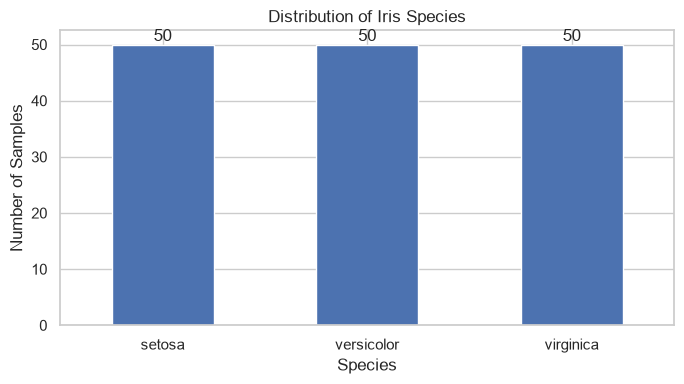

Observation: The three classes are perfectly balanced.


In [16]:
species_counts = df["species"].value_counts().reindex(iris.target_names)

display(species_counts.rename("count").to_frame())

plt.figure(figsize=(7, 4))
ax = species_counts.plot(kind="bar")
ax.set_xticklabels(iris.target_names, rotation=0)
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

if species_counts.nunique() == 1:
    print("Observation: The three classes are perfectly balanced.")
else:
    print("Observation: The class counts are not identical, so the dataset is not perfectly balanced.")

## 7. Pairplot Feature Relationships by Species

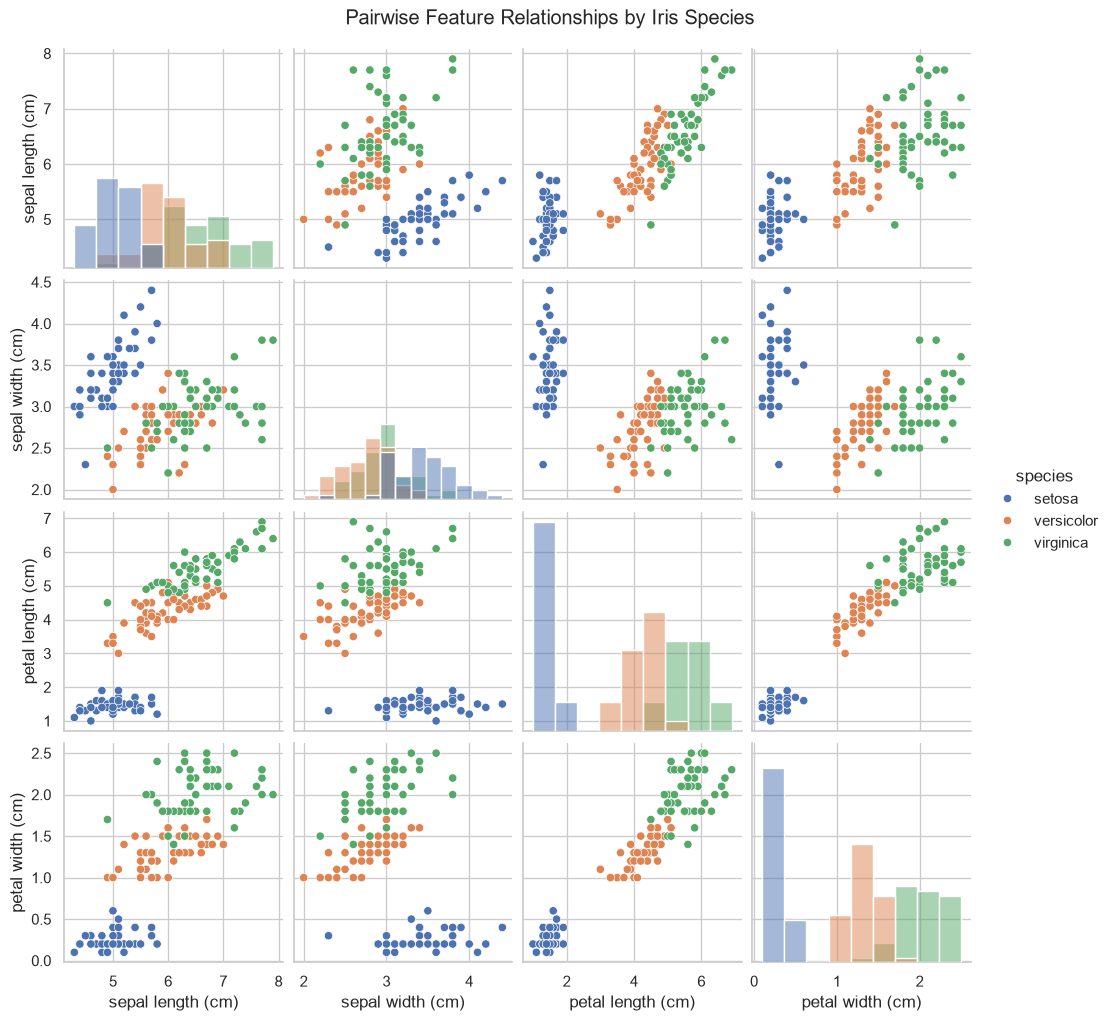

In [17]:
# Pairplot shows pairwise relationships and distributions for the four measurement features.
pairplot = sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species",
    hue_order=iris.target_names,
    diag_kind="hist"
)
pairplot.fig.suptitle("Pairwise Feature Relationships by Iris Species", y=1.02)
plt.show()

### Pairplot Observation

The pairplot provides visual evidence about class separation. **Setosa** forms a distinctly separated cluster, particularly along petal measurements. **Versicolor and Virginica** show more overlap than Setosa, although petal length and petal width provide substantial separation between them. These observations are exploratory rather than causal claims.

## 8. Box Plot Analysis

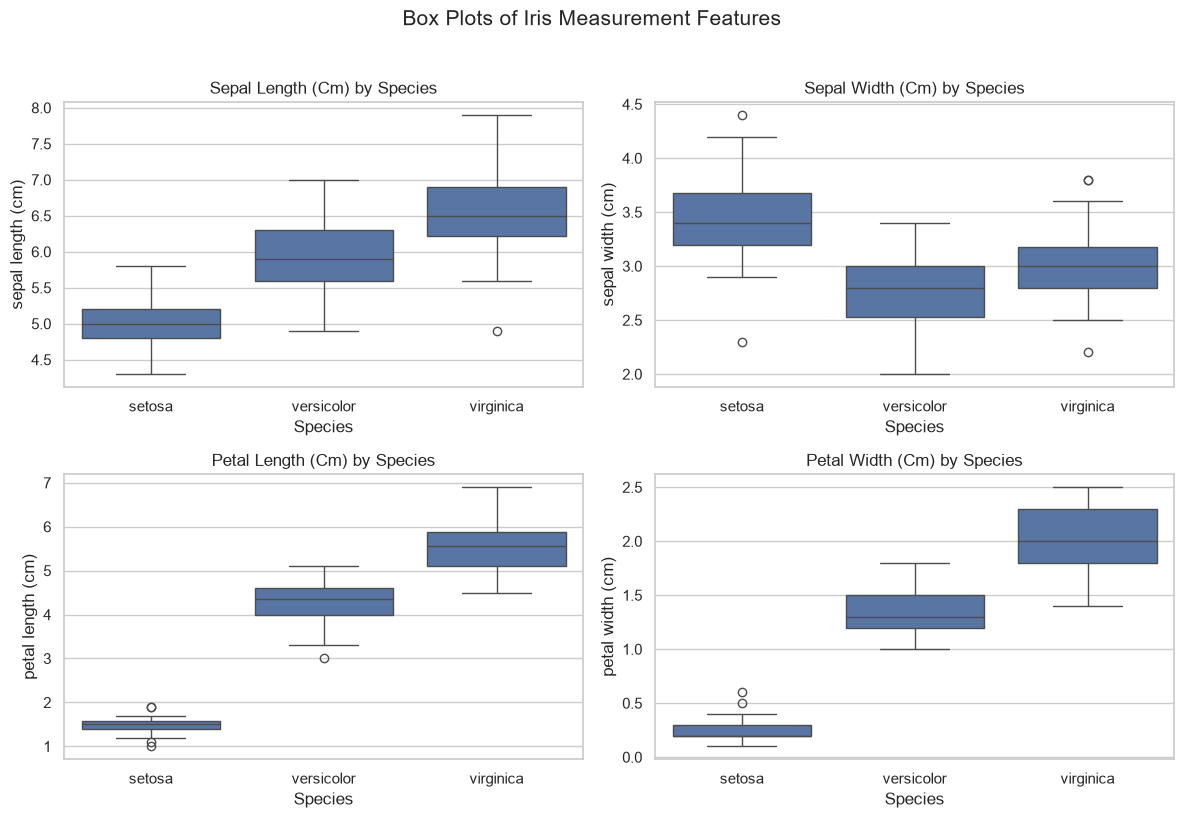

In [18]:
# Compare the distribution of every measurement across species.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, feature in zip(axes, iris.feature_names):
    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        order=iris.target_names,
        ax=ax
    )
    ax.set_title(f"{feature.title()} by Species")
    ax.set_xlabel("Species")
    ax.set_ylabel(feature)

plt.suptitle("Box Plots of Iris Measurement Features", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

### Box Plot Observation

The box plots show that **petal length and petal width** have the clearest differences in their distributions across species. Setosa is strongly separated on both petal measurements, while Versicolor and Virginica overlap more but remain distinguishable. Sepal measurements show greater overlap, especially sepal width.

## 9. Feature Selection and Feature Importance Discussion

All four original measurement features are retained for the main model comparison. This avoids arbitrary feature removal and allows the classifiers to use the complete information available in the dataset.

The exploratory visualizations suggest that petal measurements are more discriminative. To complement that evidence, a Random Forest is used to calculate model-based feature importance. This is **model-specific importance**, not a universal statement about the features.

,importance
petal length (cm),0.453793
petal width (cm),0.412449
sepal length (cm),0.115873
sepal width (cm),0.017885


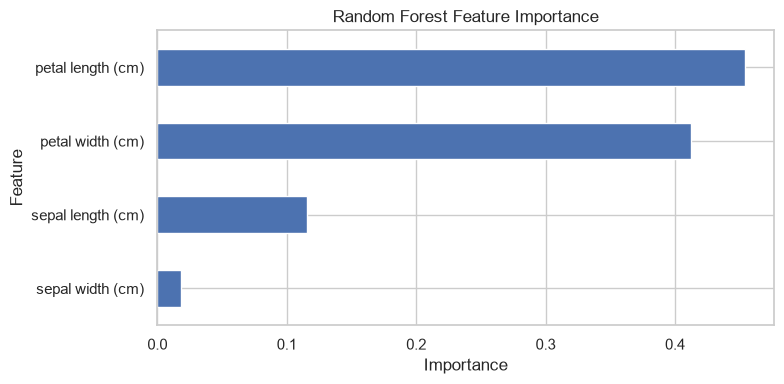

Observation: The highest model-based feature importance is assigned to 'petal length (cm)', followed by 'petal width (cm)'.


In [19]:
# Prepare the feature matrix and target before model-based analysis.
X = df[iris.feature_names]
y = df["target"]
# Reproducibility settings
RANDOM_STATE = 42
TEST_SIZE = 0.20
# Fit a Random Forest on the training data only for feature-importance analysis.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

rf_feature_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE
)
rf_feature_model.fit(X_train, y_train)

feature_importance = pd.Series(
    rf_feature_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(feature_importance.rename("importance").to_frame())

plt.figure(figsize=(8, 4))
ax = feature_importance.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(
    f"Observation: The highest model-based feature importance is assigned to "
    f"'{feature_importance.index[0]}', followed by '{feature_importance.index[1]}'."
)

## 10. Feature Matrix and Target Variable

In [20]:
# X contains the four input measurements; y contains encoded species classes.
X = df[iris.feature_names]
y = df["target"]

print("Feature matrix (X):")
display(X.head())

print("Target vector (y):")
display(y.head())

Feature matrix (X):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Target vector (y):


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

## 11. Train/Test Split

An 80/20 stratified split is used. The training set learns model parameters, while the test set remains separate for final evaluation. Stratification preserves the class proportions in both partitions.

In [21]:
# Split before fitting any preprocessing step to avoid data leakage.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining class distribution:")
display(y_train.value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))).to_frame("count"))

print("Testing class distribution:")
display(y_test.value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))).to_frame("count"))

Training feature shape: (120, 4)
Testing feature shape: (30, 4)
Training target shape: (120,)
Testing target shape: (30,)

Training class distribution:


,count
target,
setosa,40
versicolor,40
virginica,40


Testing class distribution:


,count
target,
setosa,10
versicolor,10
virginica,10


## 12. Feature Scaling

Scaling is important for **K-Nearest Neighbours** because KNN uses distances between observations. Logistic Regression also benefits from a standardized feature space in this implementation. The scaler is fitted **only on `X_train`** and then applied to both training and test data. This prevents information from the test set from influencing the learned scaling parameters.

Random Forest does not require feature scaling, so it uses the original measurement values.

In [22]:
# Fit the scaler only on training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete.")
print("Scaler was fitted on X_train only, preventing preprocessing leakage.")

Scaling complete.
Scaler was fitted on X_train only, preventing preprocessing leakage.


## 13. Classification Model 1  Logistic Regression

Logistic Regression Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



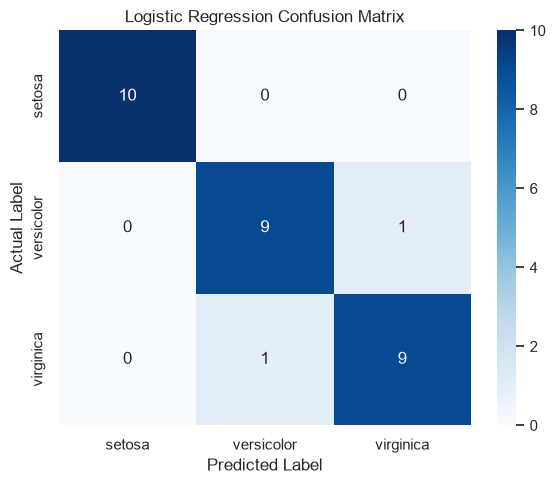

Observation: The confusion matrix and classification report above show which species were correctly classified and where errors occurred.


In [23]:
# Train Logistic Regression on standardized features.
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)
logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_cm = confusion_matrix(y_test, y_pred_logistic)
logistic_report = classification_report(
    y_test,
    y_pred_logistic,
    target_names=iris.target_names
)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f}")
print("\nClassification Report:")
print(logistic_report)

plt.figure(figsize=(6, 5))
sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Observation: The confusion matrix and classification report above show which species were correctly classified and where errors occurred.")

## 14. Classification Model 2 K-Nearest Neighbours

K-Nearest Neighbours Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



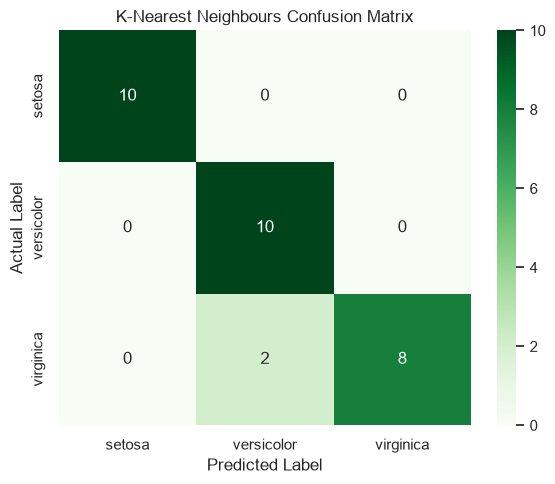

Observation: KNN's class-level precision, recall, and F1-score should be considered alongside its accuracy when comparing it with other classifiers.


In [24]:
# Train KNN on standardized features because it relies on distance calculations.
knn_model = KNeighborsClassifier(
    n_neighbors=5
)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_cm = confusion_matrix(y_test, y_pred_knn)
knn_report = classification_report(
    y_test,
    y_pred_knn,
    target_names=iris.target_names
)

print(f"K-Nearest Neighbours Accuracy: {knn_accuracy:.4f}")
print("\nClassification Report:")
print(knn_report)

plt.figure(figsize=(6, 5))
sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title("K-Nearest Neighbours Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Observation: KNN's class-level precision, recall, and F1-score should be considered alongside its accuracy when comparing it with other classifiers.")

## 15. Classification Model 3 Random Forest

A Random Forest is included because it provides a useful non-distance-based comparison and offers model-based feature importance.

Random Forest Accuracy: 0.9000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



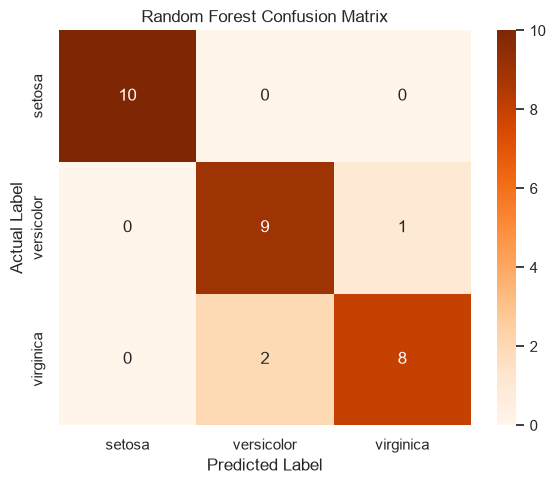

Observation: Random Forest is evaluated using the same test set and metrics, enabling a direct comparison with the other classifiers.


In [25]:
# Train Random Forest on the original feature scale.
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE
)
random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_cm = confusion_matrix(y_test, y_pred_rf)
rf_report = classification_report(
    y_test,
    y_pred_rf,
    target_names=iris.target_names
)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print("\nClassification Report:")
print(rf_report)

plt.figure(figsize=(6, 5))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Observation: Random Forest is evaluated using the same test set and metrics, enabling a direct comparison with the other classifiers.")

## 16. Consistent Model Evaluation

For each model, the notebook calculates:
- **Accuracy:** proportion of test observations classified correctly.
- **Precision:** among observations predicted as a class, the proportion that truly belongs to that class.
- **Recall:** among observations belonging to a class, the proportion correctly identified.
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** class-by-class counts of correct and incorrect predictions.

In [26]:
# Store predictions so all models can be evaluated consistently.
predictions = {
    "Logistic Regression": y_pred_logistic,
    "K-Nearest Neighbours": y_pred_knn,
    "Random Forest": y_pred_rf
}

evaluation_rows = []

for model_name, predictions_for_model in predictions.items():
    report_dict = classification_report(
        y_test,
        predictions_for_model,
        target_names=iris.target_names,
        output_dict=True
    )

    evaluation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions_for_model),
        "Macro Precision": report_dict["macro avg"]["precision"],
        "Macro Recall": report_dict["macro avg"]["recall"],
        "Macro F1": report_dict["macro avg"]["f1-score"]
    })

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.sort_values("Accuracy", ascending=False).reset_index(drop=True))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,K-Nearest Neighbours,0.933333,0.944444,0.933333,0.932660
2,Random Forest,0.900000,0.902357,0.900000,0.899749


## 17. Model Comparison

,Model,Accuracy
0,Logistic Regression,0.933333
1,K-Nearest Neighbours,0.933333
2,Random Forest,0.900000


<Figure size 900x500 with 0 Axes>

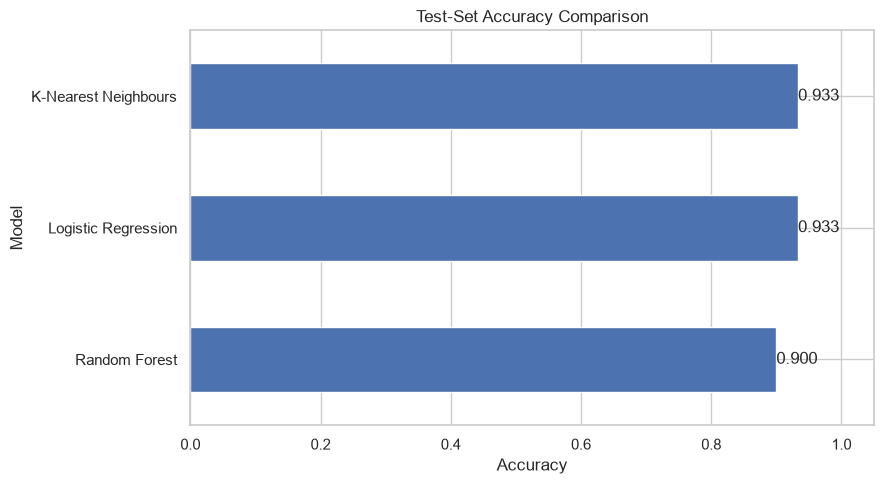

In [28]:
# Sort models by test-set accuracy; no accuracy values are hard-coded.
results = evaluation_df[["Model", "Accuracy"]].sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)


results

display(results)

plt.figure(figsize=(9, 5))
ax = results.sort_values("Accuracy").plot(
    kind="barh",
    x="Model",
    y="Accuracy",
    legend=False,
    figsize=(9, 5)
)
plt.title("Test-Set Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1.05)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f")

plt.tight_layout()
plt.show()

## 18. Best-Performing Model

In [29]:
# Select the model with the highest test-set accuracy dynamically.
best_model_name = results.iloc[0]["Model"]
best_accuracy = results.iloc[0]["Accuracy"]

best_row = evaluation_df.loc[
    evaluation_df["Model"] == best_model_name
].iloc[0]

# Check for accuracy ties and use macro F1 as a transparent secondary criterion.
tied_models = results[
    np.isclose(results["Accuracy"], best_accuracy)
]["Model"].tolist()

if len(tied_models) > 1:
    tied_details = evaluation_df[
        evaluation_df["Model"].isin(tied_models)
    ].sort_values("Macro F1", ascending=False)

    selected_model_name = tied_details.iloc[0]["Model"]
    selected_accuracy = tied_details.iloc[0]["Accuracy"]
    selection_reason = (
        f"Multiple models share the highest accuracy ({selected_accuracy:.4f}). "
        f"Macro F1 is used as a secondary criterion, selecting {selected_model_name}."
    )
else:
    selected_model_name = best_model_name
    selected_accuracy = best_accuracy
    selection_reason = (
        f"{selected_model_name} has the highest test-set accuracy ({selected_accuracy:.4f}) "
        "among the evaluated models."
    )

print(f"Best-performing model: {selected_model_name}")
print(f"Test-set accuracy: {selected_accuracy:.4f}")
print(selection_reason)

print("\nSelection context:")
display(
    evaluation_df[
        evaluation_df["Model"].isin(tied_models)
    ][["Model", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]]
    .sort_values(["Accuracy", "Macro F1"], ascending=False)
    .reset_index(drop=True)
)

Best-performing model: Logistic Regression
Test-set accuracy: 0.9333
Multiple models share the highest accuracy (0.9333). Macro F1 is used as a secondary criterion, selecting Logistic Regression.

Selection context:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,K-Nearest Neighbours,0.933333,0.944444,0.933333,0.932660


### Model-selection interpretation

The notebook selects the best model from **actual test-set results**, rather than assuming a winner in advance. Accuracy is the primary criterion because the project explicitly requires it; when accuracy is tied, macro F1 provides a transparent class-balanced secondary criterion. The confusion matrices and class-level reports should also be considered before interpreting the result.

**Important:** Test-set performance is evidence about this particular held-out sample; it does not establish universal real-world performance.

## 19. Key Findings

In [30]:
# Generate key numerical findings dynamically.
sample_count = len(df)
feature_count = len(iris.feature_names)
missing_total = int(df.isnull().sum().sum())
class_counts = df["species"].value_counts()
balanced = class_counts.nunique() == 1

top_features = feature_importance.index[:2].tolist()

best_accuracy_pct = selected_accuracy * 100

print("### Key Findings")
print(f"- Dataset size: {sample_count} samples and {feature_count} measurement features.")
print(f"- Missing values: {missing_total}.")
print(f"- Class distribution: {class_counts.to_dict()}.")
print(f"- Classes balanced: {'Yes' if balanced else 'No'}.")
print(f"- Strong exploratory/model-based feature signals: {top_features[0]} and {top_features[1]}.")
print(f"- Models evaluated: {', '.join(results['Model'])}.")
print(f"- Selected best-performing model: {selected_model_name}.")
print(f"- Selected test-set accuracy: {best_accuracy_pct:.2f}%.")

### Key Findings
- Dataset size: 150 samples and 4 measurement features.
- Missing values: 0.
- Class distribution: {np.str_('setosa'): 50, np.str_('versicolor'): 50, np.str_('virginica'): 50}.
- Classes balanced: Yes.
- Strong exploratory/model-based feature signals: petal length (cm) and petal width (cm).
- Models evaluated: Logistic Regression, K-Nearest Neighbours, Random Forest.
- Selected best-performing model: Logistic Regression.
- Selected test-set accuracy: 93.33%.


## 20. Model Limitations

- The Iris dataset is small, so a single 80/20 split can produce results that vary with a different split.
- Test-set performance on this classic dataset does not guarantee the same performance on new real-world flower populations.
- The analysis uses only four measurements and the three species represented in this dataset.
- A high score on this dataset should not be interpreted as universal generalization.
- More robust performance estimation could use cross-validation and additional validation data, although the required primary evaluation here is the held-out test set.

## 21. Conclusion

Machine learning can classify the three Iris species effectively using their physical measurements. The exploratory analysis indicates that petal length and petal width provide particularly strong class-separation signals, while the sepal measurements contain more overlap.

The evaluated classifiers provide a direct comparison of different modeling approaches. The final model selection is based on the calculated held-out test-set metrics, with class-level precision, recall, F1-score, and confusion matrices used as supporting evidence. Because this is a small, well-known dataset, the results demonstrate the workflow effectively but should not be generalized uncritically to broader real-world populations.

## 22. Dataset Source

- **Dataset:** Iris Flower Dataset
- **Primary source:** scikit-learn built-in datasets
- **Loading method:** `sklearn.datasets.load_iris()`
- **Samples:** calculated dynamically in the notebook
- **Features:** calculated dynamically in the notebook
- **Target classes:** calculated dynamically in the notebook
- **Official documentation:** https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html

## Libraries Used

- Python
- pandas
- NumPy
- matplotlib
- seaborn
- scikit-learn

## 23. Final Checklist

- [x] Iris dataset loaded using `load_iris()`
- [x] Dataset converted to pandas DataFrame
- [x] Dataset shape inspected
- [x] Data types inspected
- [x] Null values checked
- [x] Duplicate records checked
- [x] Descriptive statistics generated
- [x] Species distribution analyzed
- [x] Pairplot created
- [x] Box plots created for all four features
- [x] Feature discrimination discussed
- [x] Feature matrix and target variable created
- [x] 80/20 train/test split performed
- [x] Stratification used
- [x] Feature scaling handled correctly without leakage
- [x] At least two classification models trained
- [x] Accuracy calculated for every model
- [x] Confusion matrix generated for every model
- [x] Classification report generated for every model
- [x] Models compared programmatically
- [x] Best-performing model identified dynamically
- [x] Best model justified using calculated metrics
- [x] Key findings included
- [x] Limitations documented
- [x] Professional conclusion included
- [x] Clean and commented code
- [x] Reproducible configuration included